# 04 — Model Comparison

## Overview

This notebook compares two approaches to AG News text classification: a TF-IDF and Logistic Regression baseline, and a fine-tuned DistilBERT Transformer.

Both models are evaluated on the same official test set to compare their predictive performance and inference speed.

## Objectives

- Load the official AG News test set.
- Load the trained Logistic Regression model and TF-IDF vectorizer.
- Load the fine-tuned DistilBERT model.
- Generate predictions using both models.
- Compare accuracy, macro precision, macro recall, and macro F1-score.
- Compare inference time.
- Examine confusion matrices to understand classification errors.

## 1. Loading the Test Dataset

We load the official AG News test split, which contains 7,600 news articles across four categories.

Both models will be evaluated on the same test examples to ensure a consistent comparison.

In [1]:
# Load the AG News dataset
from datasets import load_dataset

dataset = load_dataset("fancyzhx/ag_news")

test_data = dataset["test"]

test_texts = test_data["text"]
test_labels = test_data["label"]

print("Test samples:", len(test_data))
print("Available columns:", test_data.column_names)
print("First test news:", test_texts[0])
print("First test label:", test_labels[0])

Test samples: 7600
Available columns: ['text', 'label']
First test news: Fears for T N pension after talks Unions representing workers at Turner   Newall say they are 'disappointed' after talks with stricken parent firm Federal Mogul.
First test label: 2


## 2. Loading the Trained Baseline Model

We load the saved Logistic Regression classifier and its fitted TF-IDF vectorizer.

Both artifacts are required: the vectorizer converts raw text into the numerical features expected by the classifier, and the classifier generates predictions from those features.

In [ ]:
from pathlib import Path
import urllib.request
import joblib

MODEL_DIR = Path("models/logistic_regression")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

base_url = (
    "https://raw.githubusercontent.com/"
    "RasulAramian/transformer-news-classification/main/"
    "models/logistic_regression/"
)

model_files = {
    "logistic_regression.joblib": base_url + "logistic_regression.joblib",
    "tfidf_vectorizer.joblib": base_url + "tfidf_vectorizer.joblib",
}

for filename, url in model_files.items():
    destination = MODEL_DIR / filename
    if not destination.exists():
        urllib.request.urlretrieve(url, destination)
    print(f"{filename}: {destination.stat().st_size:,} bytes")

logistic_model = joblib.load(MODEL_DIR / "logistic_regression.joblib")
tfidf_vectorizer = joblib.load(MODEL_DIR / "tfidf_vectorizer.joblib")

print("\nLogistic Regression model loaded successfully.")
print("TF-IDF vectorizer loaded successfully.")

In [3]:
import sklearn

print("Current scikit-learn version:", sklearn.__version__)

Current scikit-learn version: 1.9.1


## 3. Loading the Fine-Tuned Transformer

We load the fine-tuned DistilBERT model and its tokenizer directly from the Hugging Face Hub.

The tokenizer converts text into the token IDs and attention masks required by the Transformer. The model then uses these inputs to predict one of the four news categories.

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Load the trained model directly from Hugging Face Hub
MODEL_NAME = "RasulAramian/distilbert-ag-news"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transformer_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

transformer_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME
)

transformer_model.to(device)
transformer_model.eval()

print("DistilBERT loaded successfully.")
print("Model:", MODEL_NAME)
print("Device:", device)

## 4. Generating Baseline Predictions

We transform the test articles using the previously fitted TF-IDF vectorizer and generate predictions with Logistic Regression.

We also measure the time required for feature transformation and prediction.

In [8]:
import time

# Transform test texts into TF-IDF features
start_time = time.perf_counter()

X_test_tfidf = tfidf_vectorizer.transform(test_texts)

# Generate predictions
logistic_predictions = logistic_model.predict(X_test_tfidf)

logistic_time = time.perf_counter() - start_time

print("Logistic Regression predictions completed.")
print("Number of predictions:", len(logistic_predictions))
print(f"Inference time: {logistic_time:.2f} seconds")
print("First 10 predictions:", logistic_predictions[:10])
print("First 10 true labels:", list(test_labels[:10]))

Logistic Regression predictions completed.
Number of predictions: 7600
Inference time: 0.91 seconds
First 10 predictions: [2 3 3 1 3 3 3 3 3 3]
First 10 true labels: [2, 3, 3, 3, 3, 3, 3, 3, 3, 3]


## 5. Generating Transformer Predictions

We process the test articles in batches and use DistilBERT to generate predictions.

Batch processing limits the amount of input data processed at once. We use inference mode because the model is being evaluated rather than trained.

We also measure the time required for tokenization and prediction.

In [9]:
import time
import torch
from tqdm.auto import tqdm

transformer_predictions = []
batch_size = 32
max_length = 128

start_time = time.perf_counter()

transformer_model.eval()

with torch.inference_mode():
    for start in tqdm(range(0, len(test_texts), batch_size)):
        batch_texts = test_texts[start:start + batch_size]

        inputs = transformer_tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        outputs = transformer_model(**inputs)
        predictions = outputs.logits.argmax(dim=-1)

        transformer_predictions.extend(
            predictions.cpu().tolist()
        )

transformer_time = time.perf_counter() - start_time

print("DistilBERT predictions completed.")
print("Number of predictions:", len(transformer_predictions))
print(f"Inference time: {transformer_time:.2f} seconds")
print("First 10 predictions:", transformer_predictions[:10])
print("First 10 true labels:", list(test_labels[:10]))

  0%|          | 0/238 [00:00<?, ?it/s]

DistilBERT predictions completed.
Number of predictions: 7600
Inference time: 27.40 seconds
First 10 predictions: [2, 3, 3, 3, 3, 3, 3, 3, 3, 3]
First 10 true labels: [2, 3, 3, 3, 3, 3, 3, 3, 3, 3]


## 6. Evaluating Both Models

We evaluate both models using the same test labels.

The evaluation includes:

- **Accuracy:** The proportion of correctly classified articles.
- **Macro Precision:** Precision calculated independently for each class and then averaged.
- **Macro Recall:** Recall calculated independently for each class and then averaged.
- **Macro F1-score:** The average of the F1-scores across all four classes.

We also record inference time to compare the computational cost of the two approaches.

In [10]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_true = list(test_labels)

models_results = []

model_predictions = {
    "Logistic Regression": logistic_predictions,
    "DistilBERT": transformer_predictions,
}

model_times = {
    "Logistic Regression": logistic_time,
    "DistilBERT": transformer_time,
}

for model_name, predictions in model_predictions.items():
    models_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision (Macro)": precision_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "F1 (Macro)": f1_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "Inference Time (seconds)": model_times[model_name],
    })

results_df = pd.DataFrame(models_results)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision (Macro)": "{:.4f}",
        "Recall (Macro)": "{:.4f}",
        "F1 (Macro)": "{:.4f}",
        "Inference Time (seconds)": "{:.2f}",
    })
)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),Inference Time (seconds)
0,Logistic Regression,0.9163,0.9161,0.9163,0.9161,0.91
1,DistilBERT,0.9486,0.9488,0.9486,0.9486,27.40


## 7. Comparing Classification Metrics

We visualize the evaluation metrics for both models to make their predictive performance easier to compare.

The chart highlights differences in accuracy, macro precision, macro recall, and macro F1-score.

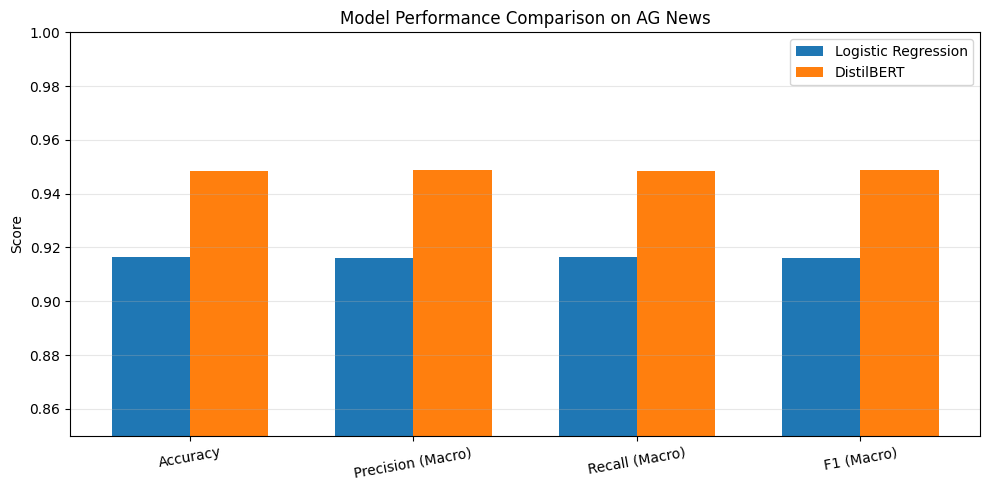

In [11]:
import matplotlib.pyplot as plt

metrics = [
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1 (Macro)",
]

x = range(len(metrics))
width = 0.35

logistic_scores = results_df.iloc[0][metrics].astype(float).values
distilbert_scores = results_df.iloc[1][metrics].astype(float).values

plt.figure(figsize=(10, 5))

plt.bar(
    [i - width / 2 for i in x],
    logistic_scores,
    width,
    label="Logistic Regression",
)

plt.bar(
    [i + width / 2 for i in x],
    distilbert_scores,
    width,
    label="DistilBERT",
)

plt.xticks(list(x), metrics, rotation=10)
plt.ylim(0.85, 1.0)
plt.ylabel("Score")
plt.title("Model Performance Comparison on AG News")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Analyzing Classification Errors

Confusion matrices show how the predictions of each model compare with the true categories.

The diagonal represents correct predictions, while off-diagonal entries represent misclassifications. Comparing the two matrices helps identify which news categories are most frequently confused.

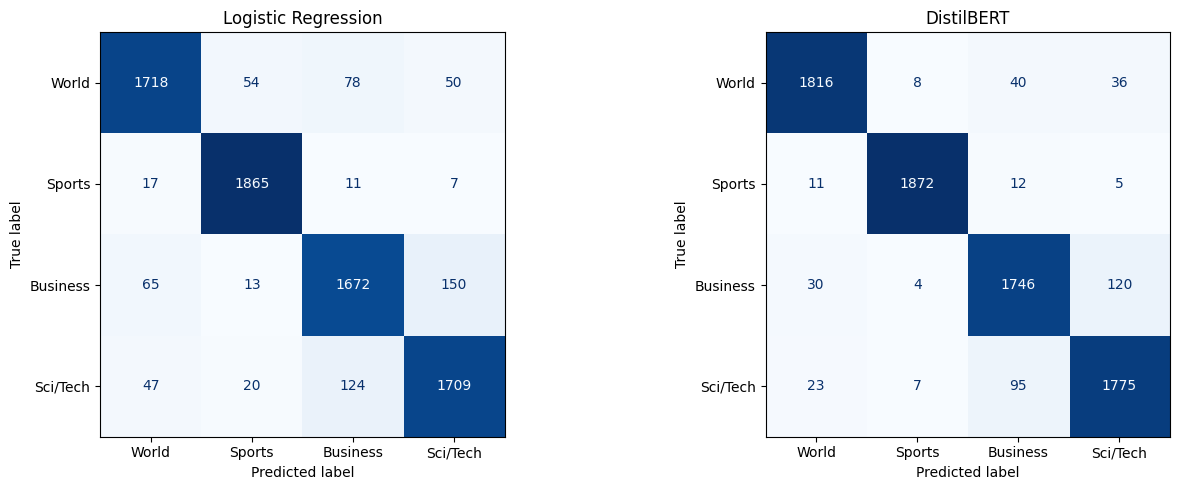

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = ["World", "Sports", "Business", "Sci/Tech"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (model_name, predictions) in zip(
    axes,
    model_predictions.items()
):
    cm = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1, 2, 3]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(model_name)

plt.tight_layout()
plt.show()

## 9. Detailed Confusion Matrix Analysis

We examine each model's confusion matrix numerically and count its correct and incorrect predictions.

This provides a more detailed view of classification errors and complements the visual comparison above.

In [14]:
from sklearn.metrics import confusion_matrix
import pandas as pd
from IPython.display import display as show_table

class_names = ["World", "Sports", "Business", "Sci/Tech"]

for model_name, predictions in model_predictions.items():
    cm = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1, 2, 3]
    )

    print(f"\n{'=' * 50}")
    print(model_name)
    print("=" * 50)

    cm_df = pd.DataFrame(
        cm,
        index=[f"Actual {name}" for name in class_names],
        columns=[f"Predicted {name}" for name in class_names]
    )

    show_table(cm_df)

    correct = cm.diagonal().sum()
    incorrect = cm.sum() - correct

    print(f"Correct predictions: {correct}")
    print(f"Incorrect predictions: {incorrect}")


Logistic Regression


,Predicted World,Predicted Sports,Predicted Business,Predicted Sci/Tech
Actual World,1718,54,78,50
Actual Sports,17,1865,11,7
Actual Business,65,13,1672,150
Actual Sci/Tech,47,20,124,1709


Correct predictions: 6964
Incorrect predictions: 636

DistilBERT


,Predicted World,Predicted Sports,Predicted Business,Predicted Sci/Tech
Actual World,1816,8,40,36
Actual Sports,11,1872,12,5
Actual Business,30,4,1746,120
Actual Sci/Tech,23,7,95,1775


Correct predictions: 7209
Incorrect predictions: 391


# Conclusion

## Model Comparison

In this notebook, TF-IDF with Logistic Regression was compared with a fine-tuned DistilBERT model on the official AG News test set containing 7,600 news articles.

The models were evaluated using the same test examples and the following metrics:

| Metric | Logistic Regression | DistilBERT |
|---|---:|---:|
| Accuracy | 91.63% | 94.86% |
| Macro Precision | 91.61% | 94.88% |
| Macro Recall | 91.63% | 94.86% |
| Macro F1-score | 91.61% | 94.86% |
| Inference Time | 0.91 seconds | 27.40 seconds |

## Key Findings

- **DistilBERT achieved higher classification performance**, with an accuracy improvement of 3.23 percentage points over Logistic Regression.
- **Logistic Regression had a shorter inference time** in this experiment.
- Logistic Regression made 636 incorrect predictions, while DistilBERT made 391.
- The confusion matrices help identify which news categories were most frequently misclassified.

## Conclusion

The results demonstrate a trade-off between predictive performance and inference speed.

DistilBERT achieved better classification performance on the AG News test set, while Logistic Regression offered faster inference and a simpler model architecture.

Inference times were measured in the current Colab environment and may vary depending on hardware, batch size, and deployment configuration.

## Next Steps

The trained models and preprocessing components can be integrated into the project's inference API. The next stage is to verify that the API loads the correct artifacts, produces valid predictions, and handles incoming requests reliably.